#HW1 - Data Exploration and Preparation

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import pylab
params = {'xtick.labelsize': 18,
          'ytick.labelsize': 18,
          'axes.titlesize' : 22,
          'axes.labelsize' : 20,
          'legend.fontsize': 18,
          'legend.title_fontsize': 22,
          'figure.titlesize': 24 }
pylab.rcParams.update(params)


## Loading the dataset

In [4]:
!rm *.csv

from google.colab import files
print("Please load the raw csv data")
uploadedData = files.upload()
filename = list(uploadedData)[0]

rm: cannot remove '*.csv': No such file or directory
Please load the raw csv data


Saving virus_data.csv to virus_data.csv


In [5]:
dataset = pd.read_csv(filename)

In [6]:
dataset.shape

(1250, 25)

In [7]:
print(dataset.conversations_per_day.value_counts())

conversations_per_day
3     218
2     204
5     179
4     168
1     108
6     107
7      94
8      54
9      42
10     29
11     16
13      8
12      7
14      6
16      5
15      3
17      1
29      1
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(dataset, test_size=0.2, random_state=123)

In [9]:
train.isnull().sum()

patient_id                0
age                       0
sex                       0
weight                    0
blood_type                0
current_location          0
num_of_siblings           0
happiness_score           0
household_income         86
conversations_per_day     0
sugar_levels              0
sport_activity            0
pcr_date                  0
PCR_01                    0
PCR_02                    0
PCR_03                    0
PCR_04                    0
PCR_05                    0
PCR_06                    0
PCR_07                    0
PCR_08                    0
PCR_09                    0
PCR_10                    0
spread                    0
risk                      0
dtype: int64

In [10]:
test.isnull().sum()

patient_id                0
age                       0
sex                       0
weight                    0
blood_type                0
current_location          0
num_of_siblings           0
happiness_score           0
household_income         23
conversations_per_day     0
sugar_levels              0
sport_activity            0
pcr_date                  0
PCR_01                    0
PCR_02                    0
PCR_03                    0
PCR_04                    0
PCR_05                    0
PCR_06                    0
PCR_07                    0
PCR_08                    0
PCR_09                    0
PCR_10                    0
spread                    0
risk                      0
dtype: int64

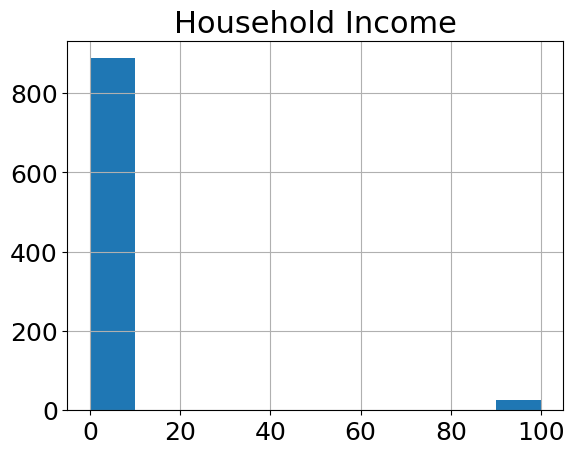

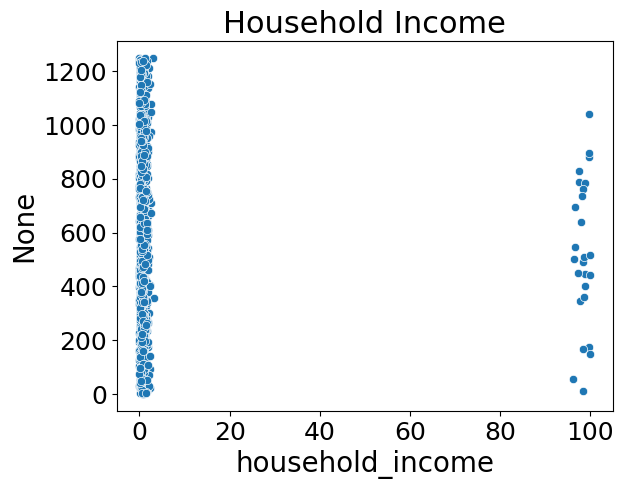

In [11]:
household_income_column = train['household_income']
household_income_column.hist()
plt.title("Household Income")
plt.show()

sns.scatterplot(x=household_income_column , y=train.index)
plt.title("Household Income")
plt.show()

In [13]:
#a.	Calculate this field's mean value in the train set and use it to
#   replace the missing values in both the train and test set.

income_mean_before_train = train['household_income'].mean()
print('mean before filling:', income_mean_before_train)
print('median before filling:', train['household_income'].median())

income_train_filled = train['household_income']
income_test_filled = test['household_income']

income_train_filled = income_train_filled.fillna(income_mean_before_train)
income_train_filled = income_test_filled.fillna(income_mean_before_train)

#(Q7)	For each field where you found missing values, calculate the median and the mean in the training set, and report it.

print('mean after filling with mean:', income_train_filled.mean())
print('median after filling with mean:', income_train_filled.median())

mean before filling: 3.5278993435448576
median before filling: 0.7
mean after filling with mean: 3.4081667396061266
median after filling with mean: 0.8


In [14]:
# b.	Like (a), but using the median instead of the mean.

income_median_before_train = train['household_income'].median()

income_train_filled_median = train['household_income']
income_test_filled_median = test['household_income']

income_train_filled_median = income_train_filled_median.fillna(income_median_before_train)
income_test_filled_median = income_test_filled_median.fillna(income_median_before_train)

#(Q7)	For each field where you found missing values, calculate the median and the mean in the training set, and report it.

print('mean after filling with median:', income_train_filled_median.mean())
print('median after filling with median:', income_train_filled_median.median())

mean after filling with median: 3.2847
median after filling with median: 0.7


In [15]:
#Task A: Use the method you chose to fill the missing values in both training and test sets.

median = train['household_income'].median()

train['household_income'] = train['household_income'].fillna(median)
test['household_income'] = test['household_income'].fillna(median)




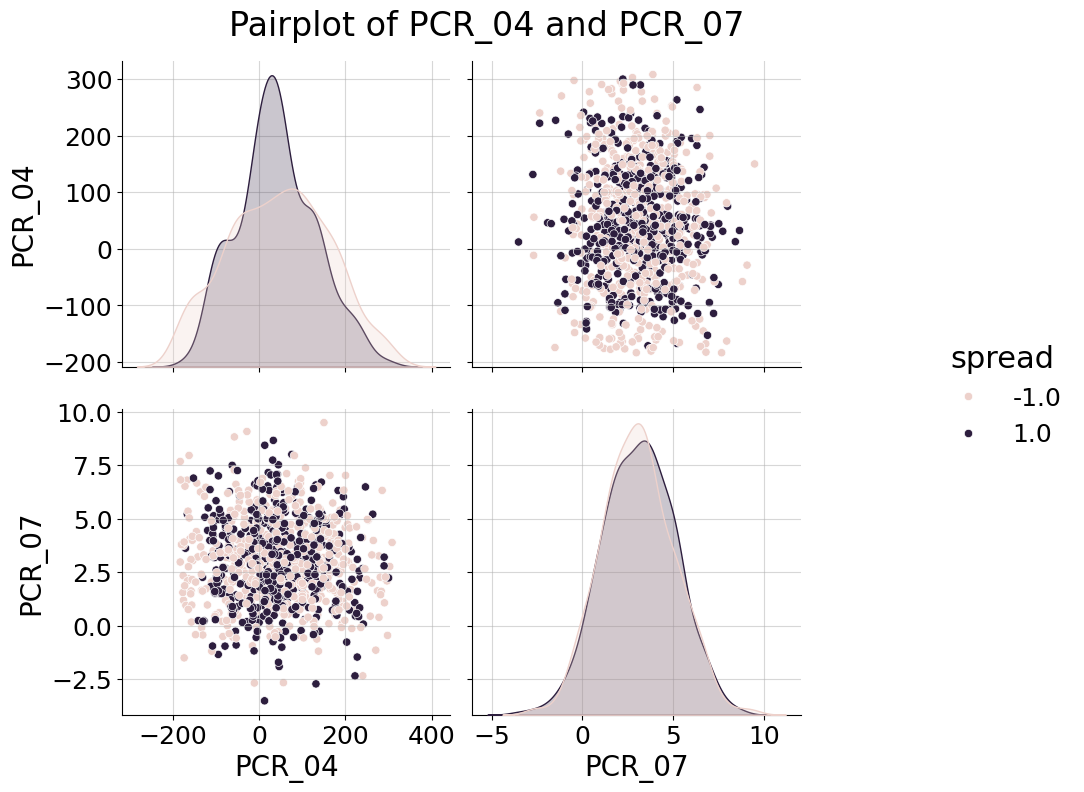

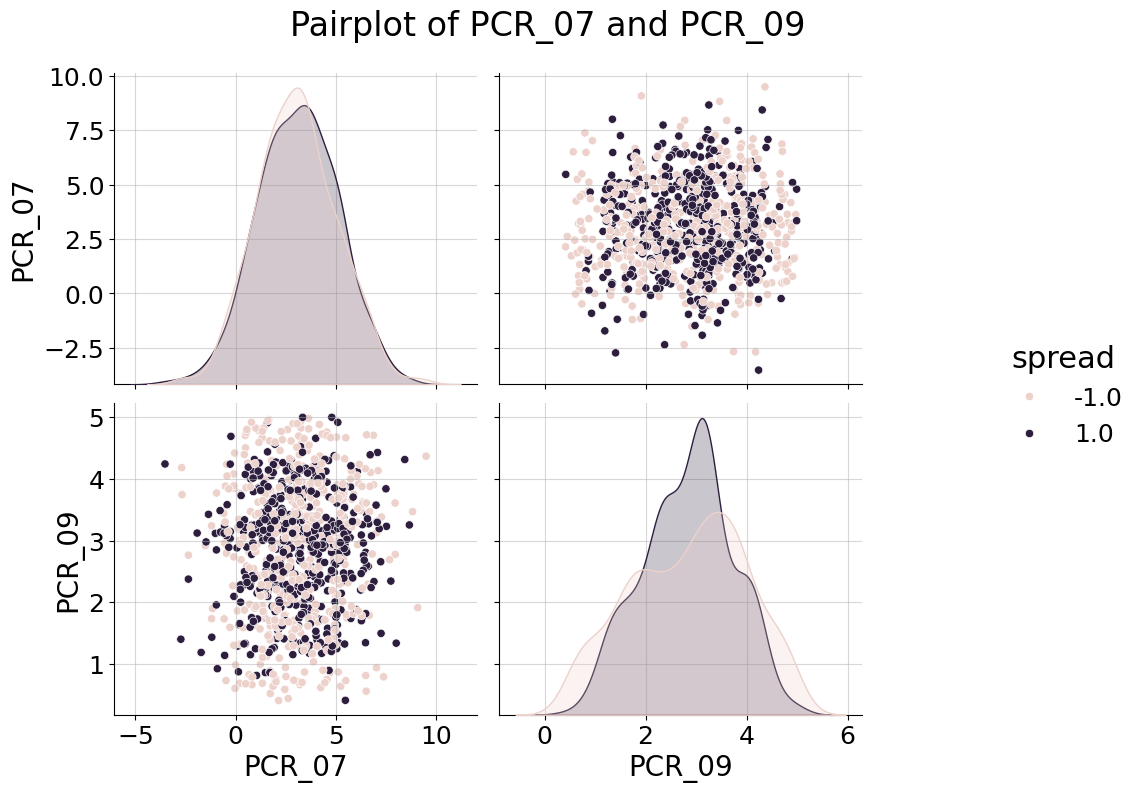

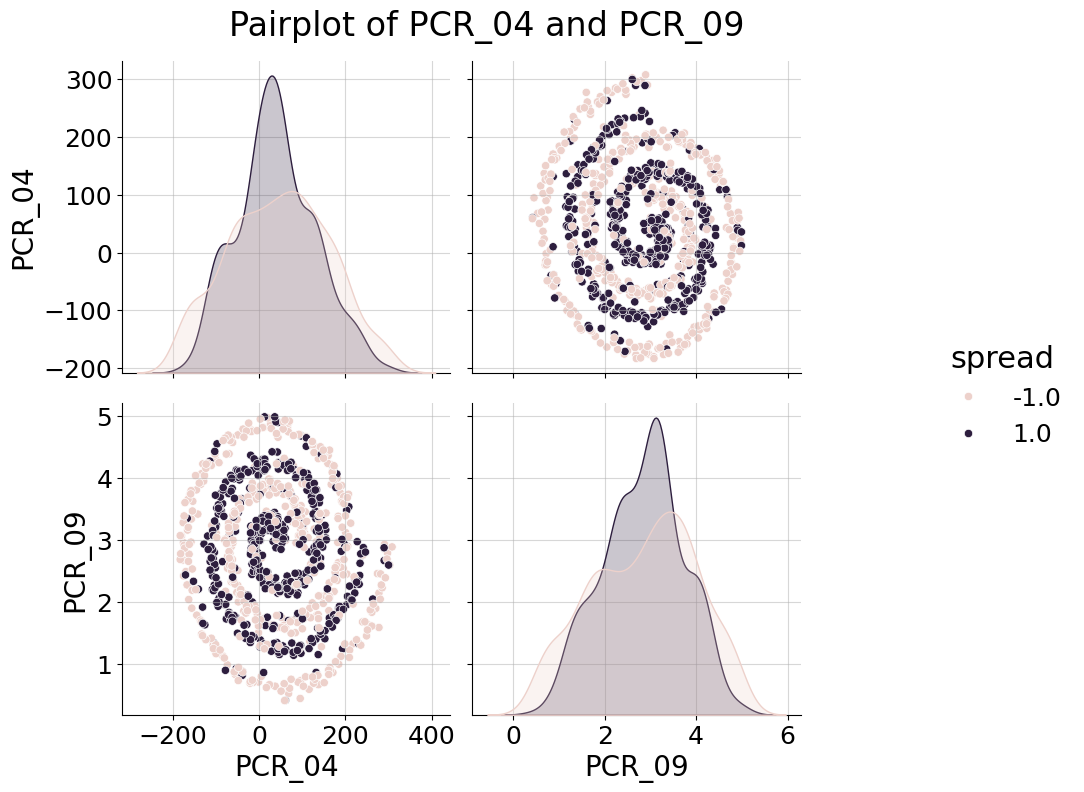

In [16]:

# Pair 4-7
pair = train[['PCR_04', 'PCR_07', 'spread']]
g = sns.pairplot(pair, vars=['PCR_04', 'PCR_07'], hue='spread')
g.fig.suptitle("Pairplot of PCR_04 and PCR_07", y=1.04)
for ax in np.ravel(g.axes):
  ax.grid(alpha=0.5)
g.fig.set_size_inches(12,8)

# Pair 7-9
pair = train[['PCR_07', 'PCR_09', 'spread']]
g = sns.pairplot(pair, vars=['PCR_07', 'PCR_09'], hue='spread')
g.fig.suptitle("Pairplot of PCR_07 and PCR_09", y=1.04)
for ax in np.ravel(g.axes):
  ax.grid(alpha=0.5)
g.fig.set_size_inches(12,8)

# Pair 4-7
pair = train[['PCR_04', 'PCR_09', 'spread']]
g = sns.pairplot(pair, vars=['PCR_04', 'PCR_09'], hue='spread')
g.fig.suptitle("Pairplot of PCR_04 and PCR_09", y=1.04)
for ax in np.ravel(g.axes):
  ax.grid(alpha=0.5)
g.fig.set_size_inches(12,8)

In [17]:
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.spatial.distance import cdist

class kNN(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors: int = 3):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        self.X_train = np.copy(X)
        self.y_train = np.copy(y)
        return self

    def predict(self, X):
        distances = cdist(X, self.X_train, 'euclidean')
        nearest_indices = np.argpartition(distances, self.n_neighbors, axis=1)[:, :self.n_neighbors]
        nearest_labels = self.y_train[nearest_indices]
        bincounts = np.apply_along_axis(np.bincount, 1, nearest_labels, minlength=np.max(self.y_train) + 1)
        predictions = np.argmax(bincounts, axis=1)

        return predictions

In [18]:
# Part 4: Task E:

dataset["blood_type"] = dataset["blood_type"].isin(["O+", "B+"])
dataset = dataset.rename(columns={"blood_type": "SpecialProperty"})


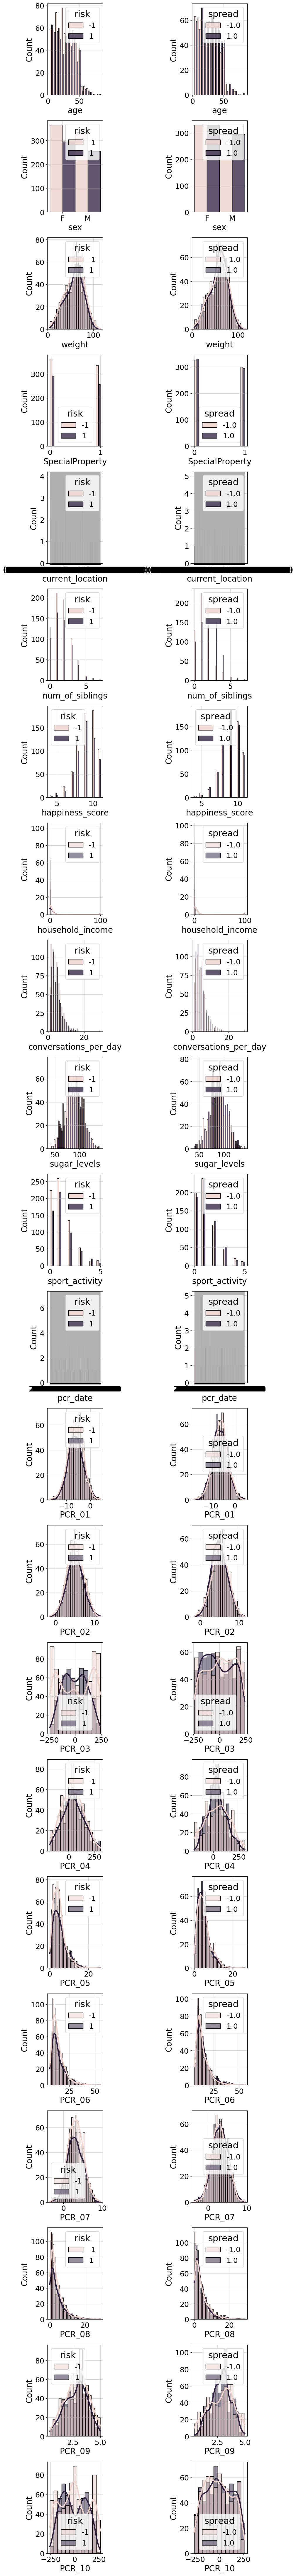

In [19]:
# Univariate Analysis

COL_NAME = ['age', 'sex', 'weight', 'SpecialProperty', 'current_location',
       'num_of_siblings', 'happiness_score', 'household_income',
       'conversations_per_day', 'sugar_levels', 'sport_activity', 'pcr_date',
       'PCR_01', 'PCR_02', 'PCR_03', 'PCR_04', 'PCR_05', 'PCR_06', 'PCR_07',
       'PCR_08', 'PCR_09', 'PCR_10']
COLS, ROWS = (2, len(COL_NAME))

plt.figure(figsize=(5 * COLS, 4 * ROWS))
for row in range(ROWS):
  column = COL_NAME[row]

  for j, cls in enumerate(["risk", "spread"]):
    plt.subplot(ROWS,COLS, row * COLS + 1 + j)

    isContinuous = "float" in dataset[column].dtype.name
    sns.histplot(data=dataset, x=column, hue=cls, line_kws={"linewidth": 3},
                 kde=isContinuous, multiple="layer" if isContinuous else "dodge")
    plt.grid(alpha=0.5)

plt.tight_layout()


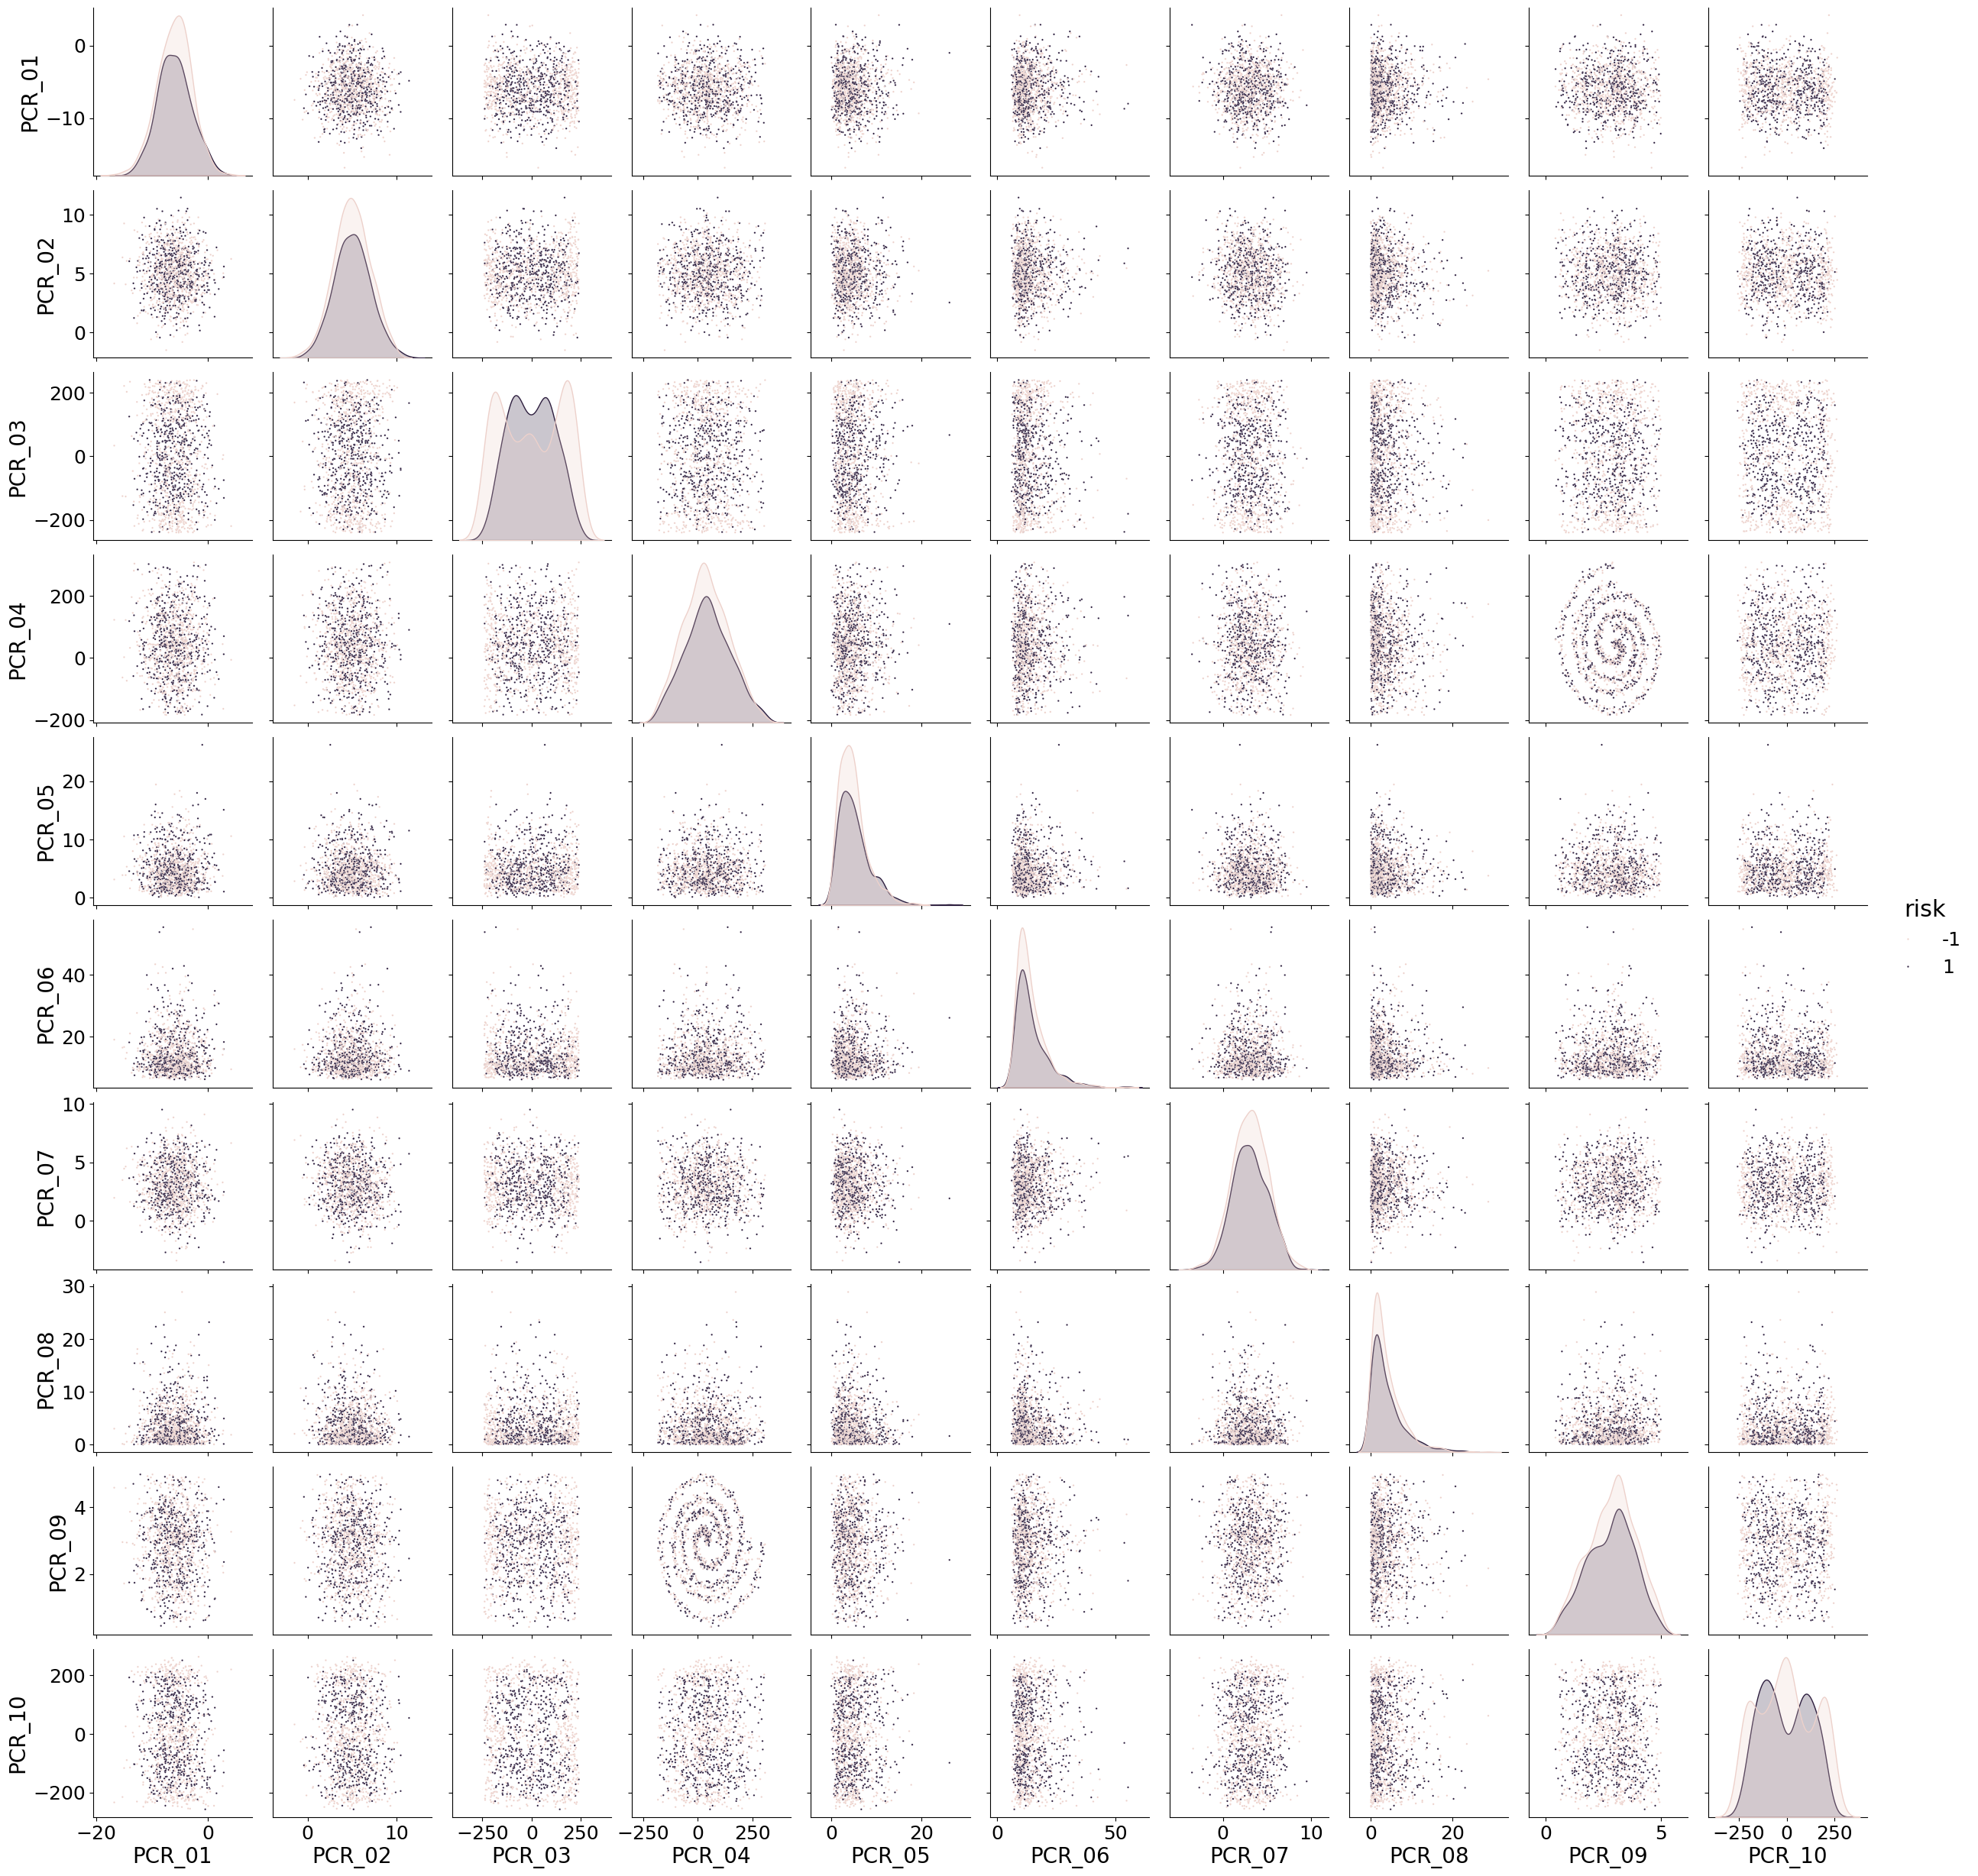

In [20]:
sns.pairplot(dataset[dataset.filter(like='PCR').columns.tolist() + ["risk"]], plot_kws={"s": 3}, hue="risk")

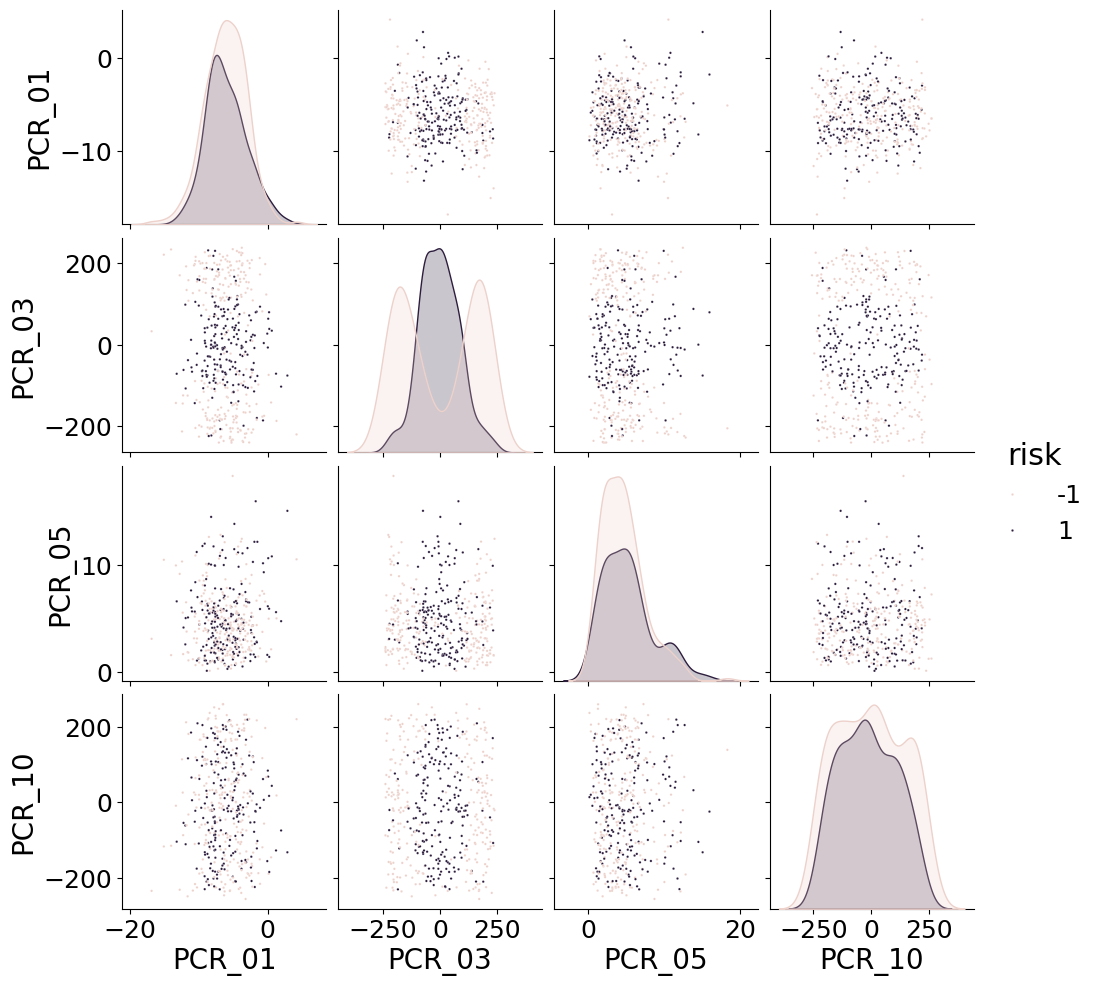

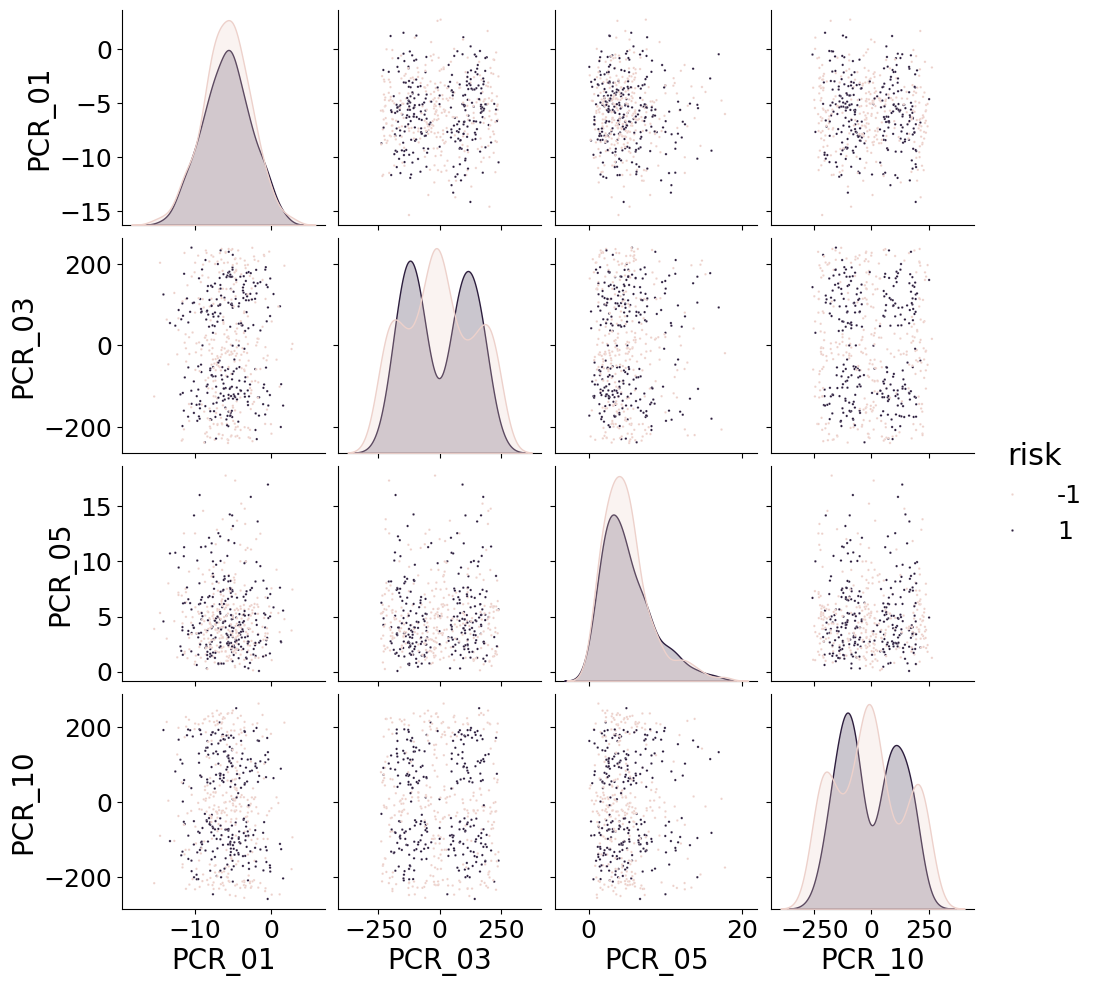

In [21]:
# Q16
train, test = train_test_split(dataset, test_size=0.2, random_state=123)
train_copy = train.copy()

train_true = train_copy[train_copy["SpecialProperty"] == True]
train_false = train_copy[train_copy["SpecialProperty"] == False]

sns.pairplot(train_true[train_true.filter(['PCR_01', 'PCR_03' , 'PCR_05' , 'PCR_10']).columns.tolist() + ["risk"]], plot_kws={"s": 3}, hue="risk")

sns.pairplot(train_false[train_false.filter(['PCR_01', 'PCR_03' , 'PCR_05' , 'PCR_10']).columns.tolist() + ["risk"]], plot_kws={"s": 3}, hue="risk")

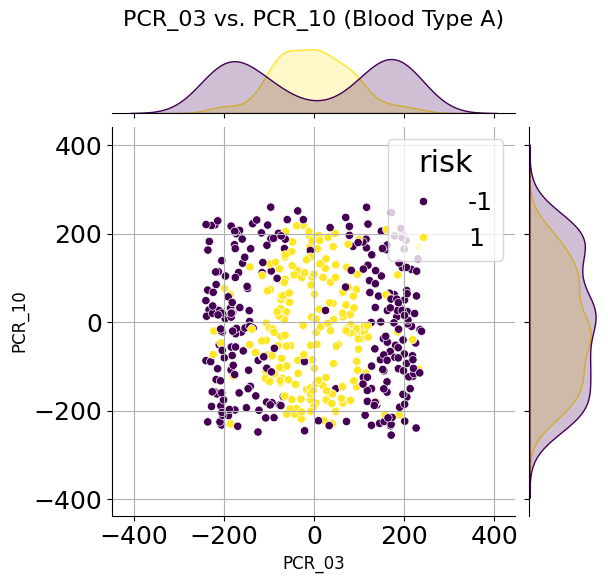

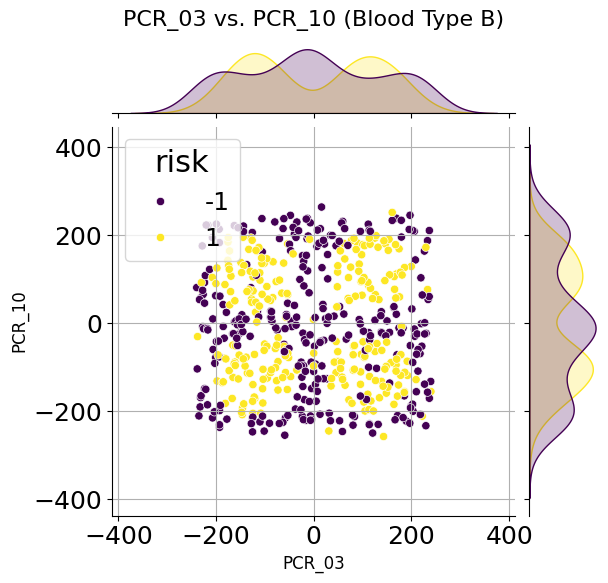

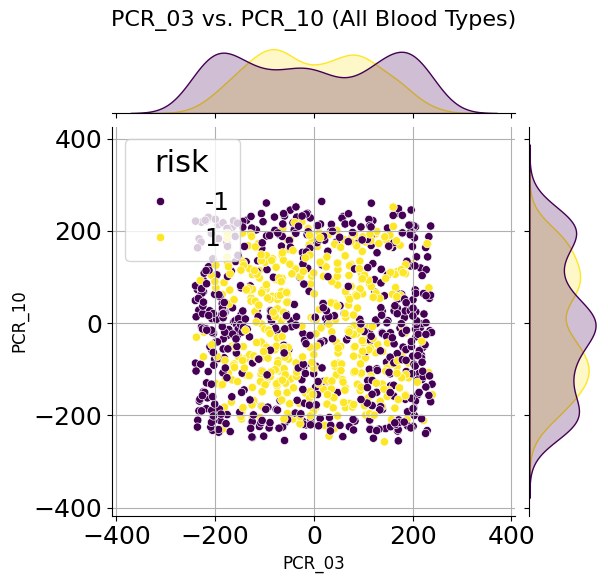

In [22]:
#Q17

joint1 = sns.jointplot(data=train_true, x='PCR_03', y='PCR_10', hue='risk', kind='scatter', palette='viridis')
joint1.ax_joint.grid(True)
joint1.fig.suptitle('PCR_03 vs. PCR_10 (Blood Type A)', fontsize=16)
joint1.set_axis_labels('PCR_03', 'PCR_10', fontsize=12)
joint1.fig.subplots_adjust(top=0.92)

joint2 = sns.jointplot(data=train_false, x='PCR_03', y='PCR_10', hue='risk', kind='scatter', palette='viridis')
joint2.ax_joint.grid(True)
joint2.fig.suptitle('PCR_03 vs. PCR_10 (Blood Type B)', fontsize=16)
joint2.set_axis_labels('PCR_03', 'PCR_10', fontsize=12)
joint2.fig.subplots_adjust(top=0.92)

joint3 = sns.jointplot(data=train, x='PCR_03', y='PCR_10', hue='risk', kind='scatter', palette='viridis')
joint3.ax_joint.grid(True)
joint3.fig.suptitle('PCR_03 vs. PCR_10 (All Blood Types)', fontsize=16)
joint3.set_axis_labels('PCR_03', 'PCR_10', fontsize=12)
joint3.fig.subplots_adjust(top=0.92)


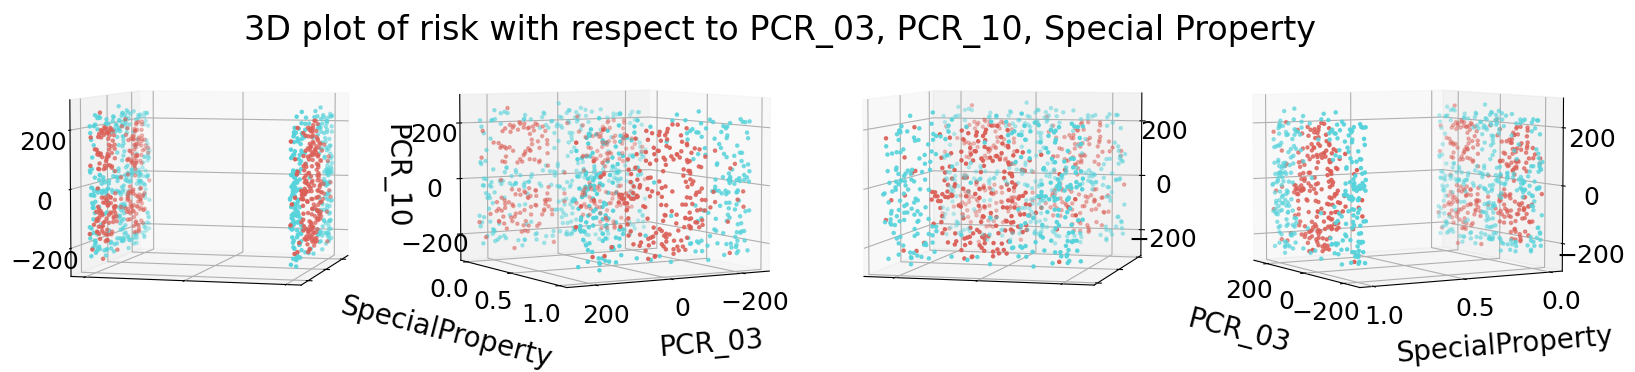

In [23]:
def plot3d(df, colX, colY, colZ, title, hue=None, s=1):
  %matplotlib inline

  fig = plt.figure(figsize=(20, 4))
  axes = [fig.add_subplot(1, 4, 1, projection='3d'),
          fig.add_subplot(1, 4, 2, projection='3d'),
          fig.add_subplot(1, 4, 3, projection='3d'),
          fig.add_subplot(1, 4, 4, projection='3d')]

  palette = sns.color_palette("hls", 2)

  for i,ax in enumerate(axes):
    if hue is None:
      ax.scatter3D(df[colX], df[colY], df[colZ], color=palette[0], s=s)
    else:
      idx = df[hue] == True
      df1 = df[idx]
      df2 = df[~idx]

      ax.scatter3D(df1[colX], df1[colY], df1[colZ], color=palette[0], s=s)
      ax.scatter3D(df2[colX], df2[colY], df2[colZ], color=palette[1], s=s)

    if i == 3 or i == 1:
      ax.set_xlabel(colX, labelpad=20)
      ax.set_ylabel(colY, labelpad=20)
    else:
      ax.xaxis.set_ticklabels([])
      ax.yaxis.set_ticklabels([])

    ax.view_init(elev=5., azim=45*i+15)

  axes[1].set_zlabel("\n" + colZ, labelpad=1)

  plt.suptitle(title)
  plt.subplots_adjust(wspace=0.1, top=0.99)
  plt.show()

plot3d(train, "PCR_03", "SpecialProperty", "PCR_10", title="3D plot of risk with respect to PCR_03, PCR_10, Special Property", hue="risk", s=5)

<ipython-input-24-ef7663a0788a>:31: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(ROWS,COLS, row * COLS + 1 + j)
<ipython-input-24-ef7663a0788a>:50: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(ROWS,COLS, row * COLS + 1 + j)


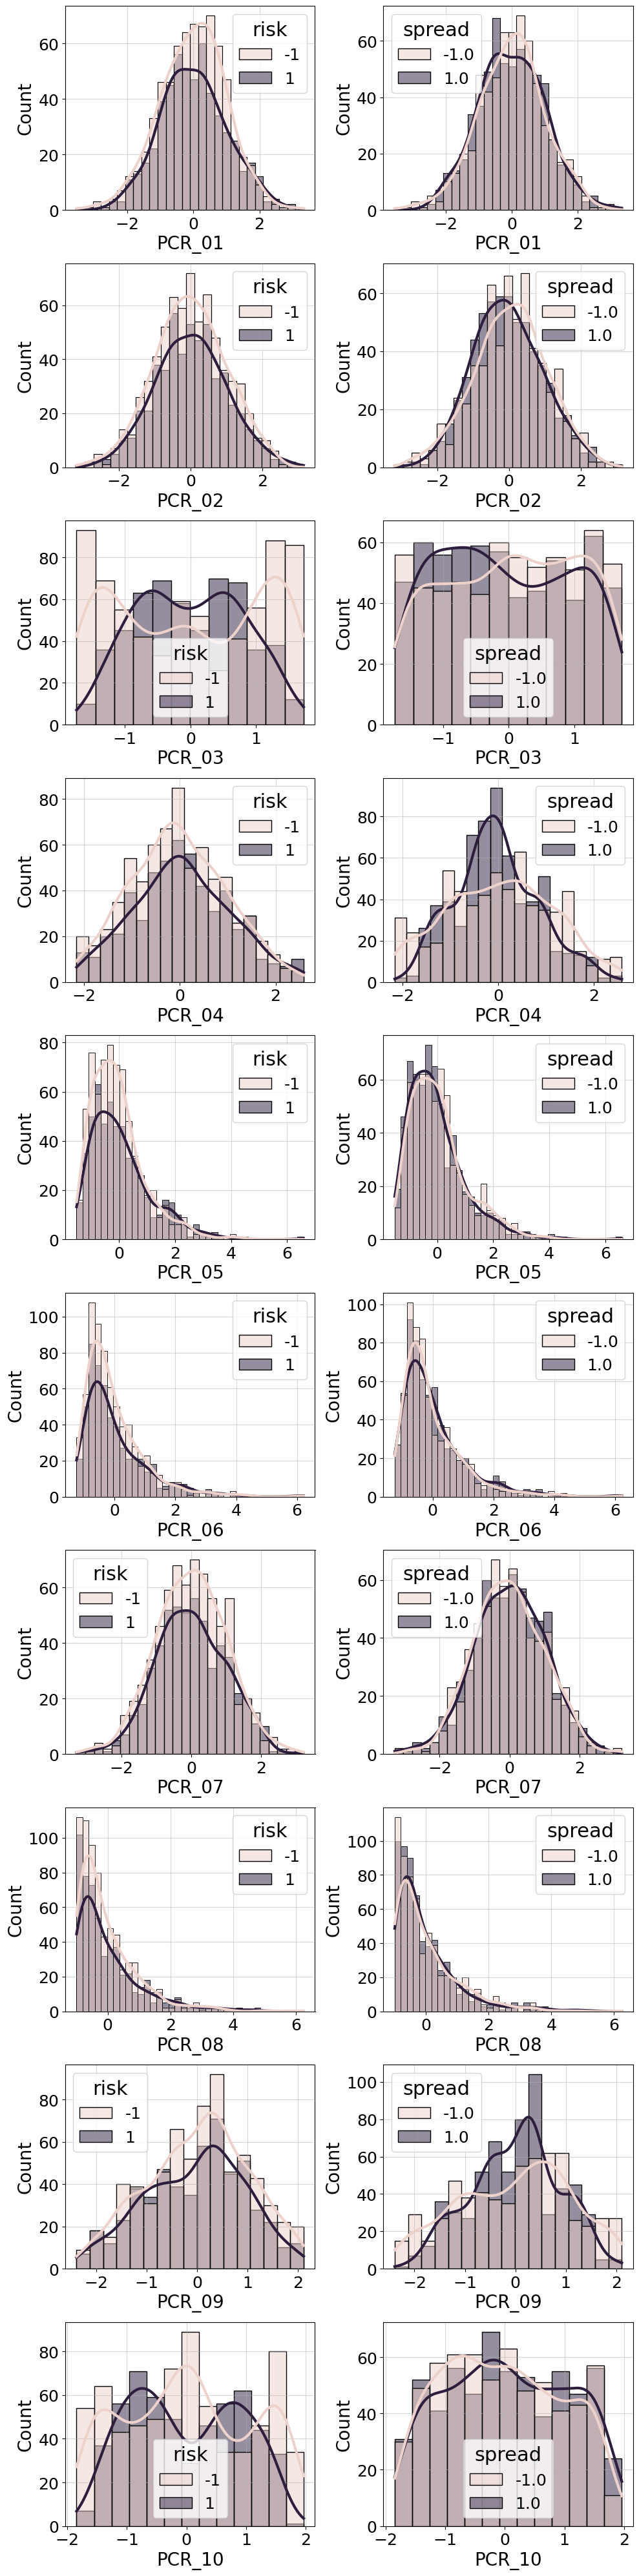

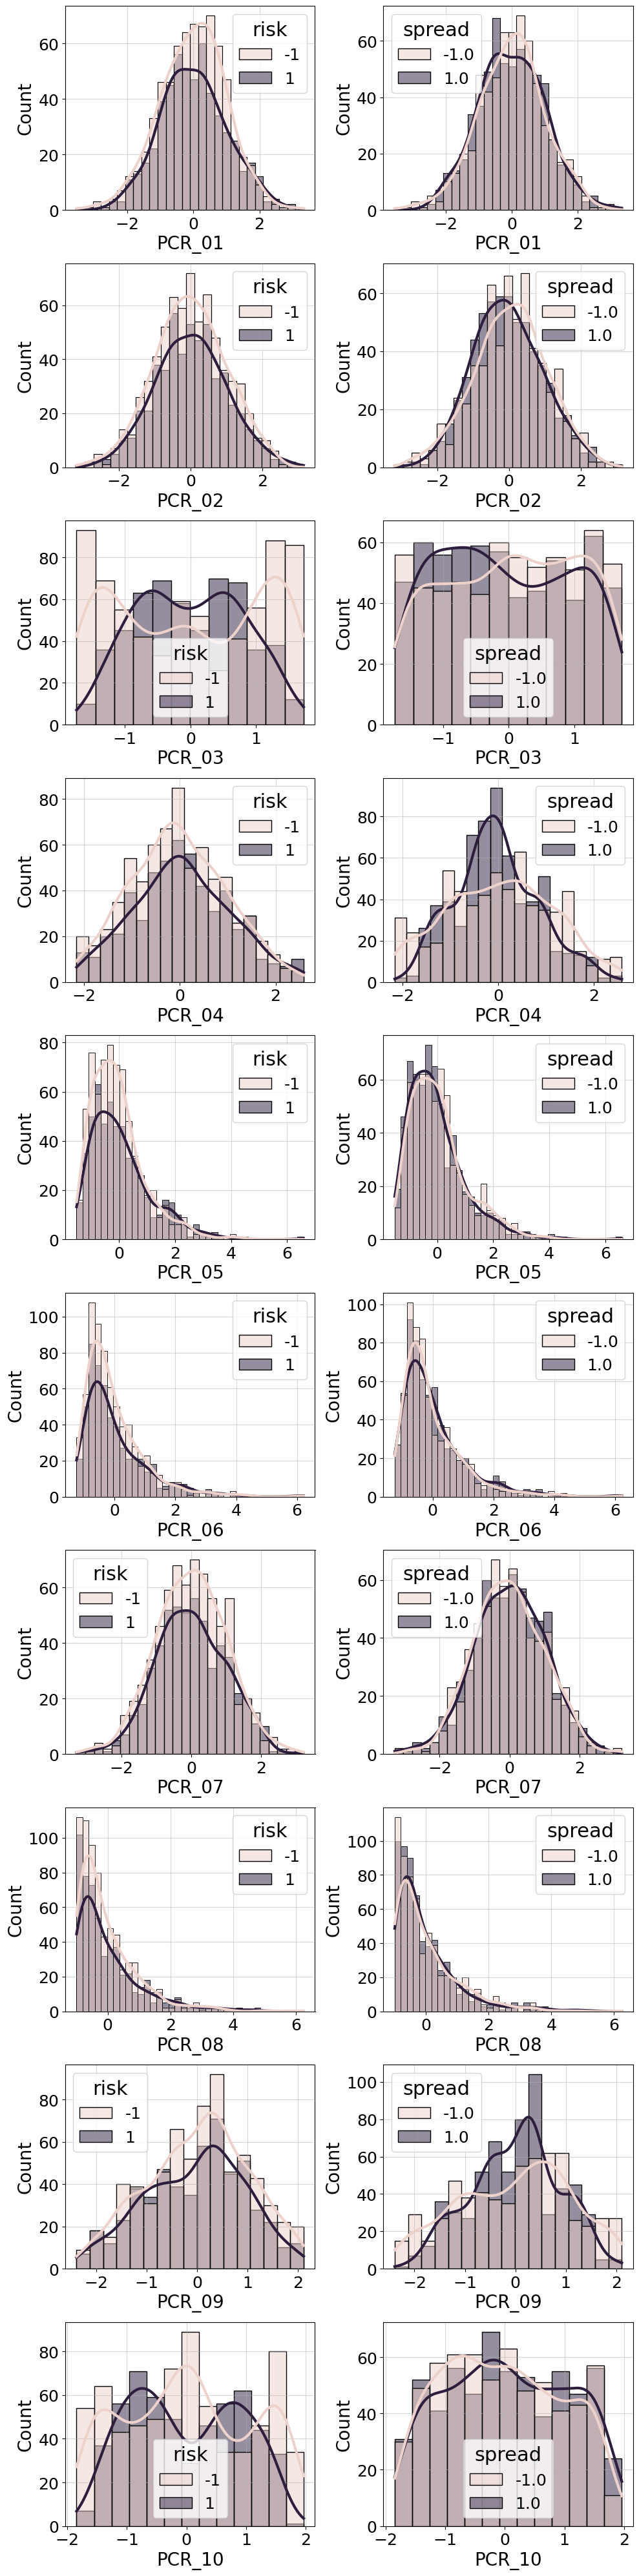

In [24]:
# Task F
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

def MinMaxScaling(data, columns):
    scaler = MinMaxScaler(feature_range=(-1, 1))
    data[columns] = scaler.fit_transform(data[columns])
    return data

def StandardScaling(data, columns):
    scaler = StandardScaler()
    data[columns] = scaler.fit_transform(data[columns])
    return data


# Univariate Analysis

COL_NAME = ['PCR_01', 'PCR_02', 'PCR_03', 'PCR_04', 'PCR_05', 'PCR_06', 'PCR_07','PCR_08', 'PCR_09', 'PCR_10']

data_minmaxed = MinMaxScaling(dataset, COL_NAME)
data_standard = StandardScaling(dataset, COL_NAME)

COLS, ROWS = (2, len(COL_NAME))

plt.figure(figsize=(5 * COLS, 4 * ROWS))
plt.title("MinMaxScaling")
for row in range(ROWS):
  column = COL_NAME[row]

  for j, cls in enumerate(["risk", "spread"]):
    plt.subplot(ROWS,COLS, row * COLS + 1 + j)

    isContinuous = "float" in data_minmaxed[column].dtype.name
    sns.histplot(data=data_minmaxed, x=column, hue=cls, line_kws={"linewidth": 3},
                 kde=isContinuous, multiple="layer" if isContinuous else "dodge")
    plt.grid(alpha=0.5)

plt.tight_layout()

#--------------------------------------------------------------

COLS, ROWS = (2, len(COL_NAME))

plt.figure(figsize=(5 * COLS, 4 * ROWS))
plt.title("StandardScaling")
for row in range(ROWS):
  column = COL_NAME[row]

  for j, cls in enumerate(["risk", "spread"]):
    plt.subplot(ROWS,COLS, row * COLS + 1 + j)

    isContinuous = "float" in data_standard[column].dtype.name
    sns.histplot(data=data_standard, x=column, hue=cls, line_kws={"linewidth": 3},
                 kde=isContinuous, multiple="layer" if isContinuous else "dodge")
    plt.grid(alpha=0.5)

plt.tight_layout()



# How to download from Colab?

In [25]:
from google.colab import files
outputPath = "saved_file.csv"
dataset.to_csv(outputPath)
files.download(outputPath)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>